# Starting Finance fund - risk analysis

Positions with a Yahoo Finance ticker are downloaded, converted to EUR and used to compute returns, volatility, drawdown, VaR and CVaR. Bonds have no ticker and are not part of the return series.

## 1. Setup

Libraries used in the notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import yfinance as yf

### Parameters

- `CAPITAL` and `LIQUIDITY`: total fund capital and cash, in EUR.
- `START_DATE`: first day of the price history.
- `CONFIDENCE_LEVEL`: confidence level of VaR and CVaR.
- `MIN_WEIGHT_COVERAGE`: minimum share of the portfolio weight that must have price data for a day to be used.

In [2]:
LIQUIDITY = 2_180_394.62
CAPITAL = 13_038_865.94

START_DATE = "2023-01-01"
CONFIDENCE_LEVEL = 0.95
MIN_WEIGHT_COVERAGE = 0.80

## 2. Data

### Fund positions

One row per position, read from a local CSV (the file uses `'` as thousands separator). Bonds have no Yahoo Finance ticker, so their ticker is empty.

In [3]:
portfolio = pd.read_csv("posizioni_fondo_ticker.csv", thousands="'")
portfolio

,ISIN,Nome,Ticker,Classe,Settore,Valuta,Quantità,Prezzo Carico,Prezzo Attuale,Investito €,Controvalore €,P&L €,P&L %,Eff. Prezzo €,Eff. Cambio €,Peso PTF %,Nota ticker
0,IE00BLNMYC90,iShares S&P 500 Equal Weight,XDEW.L,Equity,US Large Cap,EUR,6500,80.50,109.89,523251.41,714285.00,191033.59,36.51,191033.59,0.00,5.51,valuta da verificare; nome nel CSV diverso (e ...
1,IT0005436693,"BTP 0,6% Aug 2031",NaN,Fixed Income,Government Bond,EUR,7000,85.83,86.80,600810.00,607600.00,6790.00,1.13,6790.00,0.00,4.69,"obbligazione: nessun ticker, prezzo dal CSV"
2,XS2262211076,Romania 1.375% Dec 2029,NaN,Fixed Income,Government Bond,EUR,6150,89.81,91.13,552325.00,560449.50,8124.50,1.47,8124.50,0.00,4.32,"obbligazione: nessun ticker, prezzo dal CSV"
3,IT0005433690,"BTP 0,25% Mar 2028",NaN,Fixed Income,Government Bond,EUR,5200,86.14,96.23,447928.00,500396.00,52468.00,11.71,52468.00,0.00,3.86,"obbligazione: nessun ticker, prezzo dal CSV"
4,AU000XCLWAX7,"Australia 2,75% Nov 2029",NaN,Fixed Income,Government Bond,AUD,8500,56.77,94.61,482514.97,496101.75,13586.78,2.82,-967.07,14554.16,3.83,"obbligazione: nessun ticker, prezzo dal CSV"
5,GB00BJYDH287,WisdomTree Bitcoin ETP,BTCW.SW,Alternative,Crypto,EUR,28501,7.89,17.85,225007.47,453188.14,228180.67,101.41,228180.67,0.00,3.50,valuta da verificare
6,IE00BFMXXD54,Vanguard S&P 500,VUAA.L,Equity,US Large Cap,EUR,3550,115.81,127.23,411125.00,451666.51,40541.51,9.86,40541.51,0.00,3.48,valuta da verificare
7,XS2943818059,Iliad Holding 5.375% 2030,NaN,Fixed Income,Corporate Bond,EUR,4000,102.31,100.60,409240.00,402394.00,-6846.00,-1.67,-6846.00,0.00,3.10,"obbligazione: nessun ticker, prezzo dal CSV"
8,IE00BNGJJT35,Xtrackers S&P 500 Equal Weight,SPEQ.L,Equity,US Large Cap,EUR,5500,44.95,67.45,247252.50,370974.98,123722.48,50.04,123722.48,0.00,2.86,"valuta da verificare; e Invesco, nome CSV diverso"
9,IE00B53SZB19,iShares Nasdaq 100,CSNDX.SW,Equity,US Tech,EUR,250,954.67,1422.80,238667.67,355700.01,117032.34,49.04,117032.34,0.00,2.74,valuta da verificare


### Market data

Daily adjusted close prices from Yahoo Finance, for all positions that have a ticker.

- Tickers with no data at all are dropped: a column of NaN would turn the whole covariance matrix, and therefore the portfolio volatility, into NaN.
- Prices are forward-filled so that market holidays do not create gaps.

In [4]:
tickers = portfolio["Ticker"].dropna().astype(str).str.strip()
tickers = tickers[tickers != ""].unique().tolist()

data = yf.download(tickers, start=START_DATE, auto_adjust=True)["Close"]

empty = data.columns[data.isna().all()].tolist()
print("Tickers without data:", empty)
data = data.dropna(axis=1, how="all")

data = data.ffill()

[**********************63%*****                  ]  26 of 41 completed$GB00BLD4ZM24.SG: possibly delisted; no price data found  (1d 2023-01-01 -> 2026-11-11)
[*********************100%***********************]  41 of 41 completed

1 Failed download:
['GB00BLD4ZM24.SG']: possibly delisted; no price data found  (1d 2023-01-01 -> 2026-11-11)


Tickers without data: ['GB00BLD4ZM24.SG']


### Listing currencies

Each ticker is quoted in the currency of its listing, which is not always the currency of the fund. The currency is read from Yahoo Finance for every ticker; tickers whose currency is not found are printed and are not converted.

In [5]:
listing_currency = {}
for t in data.columns:
    try:
        listing_currency[t] = yf.Ticker(t).fast_info["currency"]
    except Exception:
        listing_currency[t] = None

print(pd.Series(listing_currency).value_counts(dropna=False))

unknown = [t for t, c in listing_currency.items() if c is None]
print("Currency not found:", unknown)

USD    23
EUR    13
HKD     1
CHF     1
AUD     1
GBp     1
Name: count, dtype: int64
Currency not found: []


### Conversion to EUR

Prices quoted in pence (`GBp`) are first converted to pounds. Every non-EUR series is then divided by the daily FX rate (units of foreign currency per 1 EUR), so that returns include the currency effect, as they do for a EUR-based investor.

Raw prices stay in `data` and the converted ones go to `data_eur`, so this cell can be re-run safely.

In [6]:
data_eur = data.copy()

pence = [t for t, c in listing_currency.items() if c == "GBp"]
data_eur[pence] = data_eur[pence] / 100
currency_of = {t: ("GBP" if c == "GBp" else c) for t, c in listing_currency.items()}

for currency in sorted({c for c in currency_of.values() if c not in (None, "EUR")}):
    fx = yf.download(f"EUR{currency}=X", start=START_DATE, auto_adjust=True)["Close"].squeeze()
    fx = fx.reindex(data.index).ffill().bfill()
    cols = [t for t, c in currency_of.items() if c == currency]
    data_eur[cols] = data_eur[cols].div(fx, axis=0)

data_eur.tail()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Ticker,2820.HK,2B7A.DE,AEME.PA,AFRN.PA,ASML.AS,BLTN.AS,BTCW.SW,BTEC.L,CBEU.AS,COPA.L,...,RIO.PA,SGLD.L,SPEQ.L,SPY4.L,URA,VUAA.L,XDER.L,XDEW.L,XDWH.L,XDWS.L
Date,,,,,,,,,,,,,,,,,,,,,
2026-11-05,8.269714,9.646,92.099998,113.529999,1250.000000,96.351161,16.272376,9.403695,36.099998,47.975314,...,23.174999,352.453892,66.818306,100.721457,27.574678,128.741172,24.120992,108.919093,61.237507,54.010055
2026-11-06,8.126340,9.703,93.830002,113.489998,1283.599976,96.292751,16.170817,9.391482,35.770000,47.718883,...,23.490000,347.703037,66.190132,100.104561,28.802326,128.158768,24.059204,107.861773,60.080547,52.973480
2026-11-09,8.241990,9.780,95.139999,113.589996,1343.800049,97.153771,16.088708,9.697436,36.419998,48.648650,...,23.570000,355.171941,67.774400,103.478181,30.805729,130.596914,24.273095,110.448497,61.297481,53.241699
2026-11-10,8.269834,9.767,95.230003,113.610001,1361.000000,94.756382,15.747638,9.516628,36.660000,47.458388,...,23.360001,344.674792,67.142125,102.410677,29.538972,129.383364,24.261263,109.378845,60.753154,53.054310
2026-11-11,8.367037,9.840,98.559998,113.599998,1403.800049,96.822822,15.957666,9.705724,37.810001,48.497064,...,23.740000,346.971736,68.620776,104.648710,30.582270,132.841739,24.090435,111.744305,61.489116,53.509958


## 3. Returns and asset statistics

### Daily log returns (EUR)

In [7]:
returns = np.log(data_eur / data_eur.shift(1)).iloc[1:]
returns

Ticker,2820.HK,2B7A.DE,AEME.PA,AFRN.PA,ASML.AS,BLTN.AS,BTCW.SW,BTEC.L,CBEU.AS,COPA.L,...,RIO.PA,SGLD.L,SPEQ.L,SPY4.L,URA,VUAA.L,XDER.L,XDEW.L,XDWH.L,XDWS.L
Date,,,,,,,,,,,,,,,,,,,,,
2023-01-03,NaN,-0.015435,0.012660,-0.003020,0.006556,NaN,NaN,NaN,NaN,NaN,...,-0.014370,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-04,0.022595,0.019485,0.018311,0.000615,0.031592,NaN,0.001951,0.013571,NaN,-0.001547,...,-0.012370,0.028274,0.028023,0.023800,0.015323,0.025813,0.025424,0.020997,0.020049,0.024697
2023-01-05,0.026217,-0.017625,0.008625,-0.000107,0.005386,NaN,0.008606,-0.005420,NaN,0.014822,...,0.026620,-0.020664,-0.015771,-0.016410,-0.004134,-0.020098,-0.007747,0.002965,-0.016552,-0.017071
2023-01-06,-0.007719,0.010954,0.009055,0.001532,0.021258,NaN,-0.003466,0.028003,NaN,0.029171,...,0.041171,0.024561,0.027515,0.030557,0.059333,0.023970,-0.001929,0.012823,0.016119,0.027908
2023-01-09,-0.003160,-0.001182,0.007492,-0.000548,0.061701,NaN,0.011955,-0.022224,NaN,0.024801,...,-0.019906,-0.004910,0.005362,0.000597,0.004662,0.008080,0.019548,0.008332,-0.006924,-0.000999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-05,0.028373,-0.002071,-0.043866,0.000352,-0.067733,-0.000064,-0.049976,-0.017033,-0.041243,-0.015921,...,-0.000863,0.014493,-0.018721,-0.021030,-0.056502,-0.029613,0.002177,-0.016910,-0.001305,-0.000489
2026-11-06,-0.017489,0.005892,0.018610,-0.000352,0.026525,-0.000606,-0.006261,-0.001300,-0.009183,-0.005359,...,0.013501,-0.013571,-0.009446,-0.006144,0.043558,-0.004534,-0.002565,-0.009755,-0.019074,-0.019379
2026-11-09,0.014131,0.007904,0.013865,0.000881,0.045833,0.008902,-0.005090,0.032058,0.018008,0.019297,...,0.003400,0.021253,0.023653,0.033146,0.067245,0.018846,0.008851,0.023699,0.020053,0.005050


### Per-asset statistics

Daily mean, standard deviation and variance of the log returns of each asset.

In [8]:
statistics_assets = pd.DataFrame({
    "Mean Return": returns.mean(),
    "Std Dev": returns.std(),
    "Variance": returns.var(),
})
statistics_assets

,Mean Return,Std Dev,Variance
Ticker,,,
2820.HK,0.000139,0.018846,3.551635e-04
2B7A.DE,0.000254,0.012528,1.569422e-04
AEME.PA,0.000554,0.010751,1.155872e-04
AFRN.PA,0.000125,0.000835,6.967023e-07
ASML.AS,0.001036,0.024020,5.769678e-04
BLTN.AS,0.000400,0.012303,1.513603e-04
BTCW.SW,0.001432,0.028850,8.323286e-04
BTEC.L,0.000541,0.012351,1.525491e-04
CBEU.AS,0.000743,0.015442,2.384405e-04


### Correlation matrix

In [9]:
correlation_matrix = returns.corr()
correlation_matrix

Ticker,2820.HK,2B7A.DE,AEME.PA,AFRN.PA,ASML.AS,BLTN.AS,BTCW.SW,BTEC.L,CBEU.AS,COPA.L,...,RIO.PA,SGLD.L,SPEQ.L,SPY4.L,URA,VUAA.L,XDER.L,XDEW.L,XDWH.L,XDWS.L
Ticker,,,,,,,,,,,,,,,,,,,,,
2820.HK,1.000000,0.011932,0.291942,-0.090000,0.086219,0.077384,0.099217,0.202677,0.125985,0.152825,...,0.105877,0.139362,0.174632,0.144818,0.119489,0.206954,0.106465,0.113505,0.157594,0.075579
2B7A.DE,0.011932,1.000000,0.114538,0.007965,0.018364,-0.021109,0.025916,0.164758,0.021652,-0.022372,...,0.118439,0.063565,0.273299,0.193645,0.051221,0.159881,0.432146,0.211897,0.226712,0.280840
AEME.PA,0.291942,0.114538,1.000000,-0.046205,0.578710,0.302969,0.247250,0.350507,0.393260,0.385129,...,0.415846,0.222155,0.451792,0.517449,0.401535,0.568995,0.247076,0.340204,0.165028,0.036826
AFRN.PA,-0.090000,0.007965,-0.046205,1.000000,-0.035622,-0.020420,0.061045,0.007393,0.043339,-0.001338,...,0.016495,-0.052064,0.024084,0.033054,-0.045192,0.002033,0.032445,0.092824,0.004535,-0.035742
ASML.AS,0.086219,0.018364,0.578710,-0.035622,1.000000,0.184383,0.191411,0.217872,0.312599,0.239392,...,0.212984,0.071377,0.335111,0.419253,0.285171,0.497455,0.135628,0.255422,0.100680,-0.072216
BLTN.AS,0.077384,-0.021109,0.302969,-0.020420,0.184383,1.000000,0.175843,0.247481,0.016052,0.332906,...,0.797671,0.228375,0.288780,0.275696,0.298817,0.323079,0.179646,0.300502,0.186193,0.170765
BTCW.SW,0.099217,0.025916,0.247250,0.061045,0.191411,0.175843,1.000000,0.160535,0.273852,0.097690,...,0.134064,0.090129,0.215065,0.247849,0.153321,0.294667,0.078799,0.185090,0.063168,-0.025738
BTEC.L,0.202677,0.164758,0.350507,0.007393,0.217872,0.247481,0.160535,1.000000,0.264669,0.211904,...,0.230680,0.192455,0.619015,0.588707,0.226350,0.552855,0.271322,0.421023,0.753092,0.382015
CBEU.AS,0.125985,0.021652,0.393260,0.043339,0.312599,0.016052,0.273852,0.264669,1.000000,0.147554,...,0.150287,0.017551,0.441581,0.475881,0.194914,0.540883,0.136493,0.358830,0.140676,-0.043478


### Covariance matrix

In [10]:
covariance_matrix = returns.cov()
covariance_matrix

Ticker,2820.HK,2B7A.DE,AEME.PA,AFRN.PA,ASML.AS,BLTN.AS,BTCW.SW,BTEC.L,CBEU.AS,COPA.L,...,RIO.PA,SGLD.L,SPEQ.L,SPY4.L,URA,VUAA.L,XDER.L,XDEW.L,XDWH.L,XDWS.L
Ticker,,,,,,,,,,,,,,,,,,,,,
2820.HK,3.551635e-04,2.816181e-06,5.914354e-05,-1.406295e-06,3.904784e-05,2.051277e-05,0.000054,4.717633e-05,3.785202e-05,4.787210e-05,...,3.283684e-05,3.251591e-05,3.030080e-05,3.117144e-05,5.871528e-05,3.696913e-05,2.743340e-05,2.561442e-05,2.728706e-05,1.173216e-05
2B7A.DE,2.816181e-06,1.569422e-04,1.542678e-05,8.328574e-08,5.525988e-06,-2.638653e-06,0.000009,2.548578e-05,4.283820e-06,-4.657108e-06,...,2.441554e-05,9.856058e-06,3.151372e-05,2.769951e-05,1.672641e-05,1.897987e-05,7.400054e-05,3.177781e-05,2.608694e-05,2.897133e-05
AEME.PA,5.914354e-05,1.542678e-05,1.155872e-04,-4.146327e-07,1.494485e-04,5.332061e-05,0.000077,4.653693e-05,6.733556e-05,6.881396e-05,...,7.356811e-05,2.956575e-05,4.471479e-05,6.353070e-05,1.125451e-04,5.797703e-05,3.631505e-05,4.379143e-05,1.629886e-05,3.260745e-06
AFRN.PA,-1.406295e-06,8.328574e-08,-4.146327e-07,6.967023e-07,-7.142022e-07,-1.813216e-07,0.000001,7.571389e-08,4.869463e-07,-1.843522e-08,...,2.265533e-07,-5.344361e-07,1.838504e-07,3.130158e-07,-9.769834e-07,1.598120e-08,3.678157e-07,9.215879e-07,3.454733e-08,-2.440981e-07
ASML.AS,3.904784e-05,5.525988e-06,1.494485e-04,-7.142022e-07,5.769678e-04,6.277712e-05,0.000133,6.466789e-05,1.198602e-04,9.562401e-05,...,8.418297e-05,2.123628e-05,7.414592e-05,1.150744e-04,1.786878e-04,1.133149e-04,4.456486e-05,7.350112e-05,2.222954e-05,-1.429491e-05
BLTN.AS,2.051277e-05,-2.638653e-06,5.332061e-05,-1.813216e-07,6.277712e-05,1.513603e-04,0.000056,4.215242e-05,3.897185e-06,6.337662e-05,...,2.229819e-04,4.746460e-05,2.592207e-05,3.264028e-05,1.168611e-04,3.213575e-05,2.328222e-05,2.687884e-05,2.375355e-05,2.084455e-05
BTCW.SW,5.394471e-05,9.364072e-06,7.667971e-05,1.460232e-06,1.327079e-04,5.588139e-05,0.000832,5.720328e-05,1.176005e-04,4.684602e-05,...,6.365077e-05,3.219195e-05,5.712597e-05,8.166859e-05,1.153338e-04,8.058062e-05,3.108323e-05,6.394157e-05,1.674347e-05,-6.116229e-06
BTEC.L,4.717633e-05,2.548578e-05,4.653693e-05,7.571389e-08,6.466789e-05,4.215242e-05,0.000057,1.525491e-04,5.188407e-05,4.350297e-05,...,4.688783e-05,2.942876e-05,7.039186e-05,8.304702e-05,7.289404e-05,6.472428e-05,4.581944e-05,6.226791e-05,8.545873e-05,3.886421e-05
CBEU.AS,3.785202e-05,4.283820e-06,6.733556e-05,4.869463e-07,1.198602e-04,3.897185e-06,0.000118,5.188407e-05,2.384405e-04,3.891439e-05,...,3.820390e-05,3.471650e-06,6.031841e-05,8.156794e-05,8.158345e-05,7.806653e-05,2.807340e-05,6.696322e-05,2.018375e-05,-5.561141e-06


## 4. Portfolio

### Weights

Current portfolio weights, assumed constant over the whole history (a backtest of today's allocation). They are rescaled to 100% over the assets with a ticker, since bonds are not part of the return series. `analysed_value` is the EUR value of the positions covered by the analysis.

In [11]:
weight = portfolio.dropna(subset=["Ticker"]).set_index("Ticker")["Peso PTF %"] / 100
weight = weight.reindex(returns.columns).dropna()
weight = weight / weight.sum()

analysed_value = portfolio.loc[portfolio["Ticker"].isin(weight.index), "Controvalore €"].sum()
print(f"Analysed value: {analysed_value:,.0f} EUR ({analysed_value / CAPITAL:.1%} of fund capital)")

Analysed value: 7,377,749 EUR (56.6% of fund capital)


### Portfolio returns

Some ETFs were launched recently and have no data in the early months. Instead of treating missing returns as 0%, the weights are rescaled day by day over the assets that have a return on that day. Days where less than `MIN_WEIGHT_COVERAGE` of the weight has data are dropped.

In [12]:
r = returns[weight.index]

w_raw = r.notna().mul(weight, axis=1)
coverage = w_raw.sum(axis=1)
w_day = w_raw.div(coverage, axis=0)

portfolio_returns = (r.fillna(0) * w_day).sum(axis=1)
portfolio_returns = portfolio_returns[coverage >= MIN_WEIGHT_COVERAGE]

print("First day used:", portfolio_returns.index[0].date(), "| trading days:", len(portfolio_returns))

First day used: 2023-01-04 | trading days: 996


### Return and volatility

Mean return and standard deviation of the portfolio, daily and annualised (252 trading days).

In [13]:
print("Mean daily return:", portfolio_returns.mean())
print("Daily std dev:", portfolio_returns.std())
print("Annualised return:", portfolio_returns.mean() * 252)
print("Annualised volatility:", portfolio_returns.std() * np.sqrt(252))

Mean daily return: 0.0005908374540160248
Daily std dev: 0.008167506663311697
Annualised return: 0.14889103841203827
Annualised volatility: 0.1296551487755142


### Volatility from the covariance matrix

Second estimate of the portfolio volatility, `sqrt(w' Cov w)`, which uses the static weights.

In [14]:
cov = covariance_matrix.loc[weight.index, weight.index]
w = weight.to_numpy()

portfolio_variance = w @ cov.to_numpy() @ w
portfolio_volatility = np.sqrt(portfolio_variance)
print("Daily volatility:", portfolio_volatility)
print("Annualised volatility:", portfolio_volatility * np.sqrt(252))

Daily volatility: 0.008366864629609515
Annualised volatility: 0.13281985837973595


## 5. Risk measures

### Equity curve

Backtest of today's weights. The curve is scaled so that its last value equals the current value of the analysed positions.

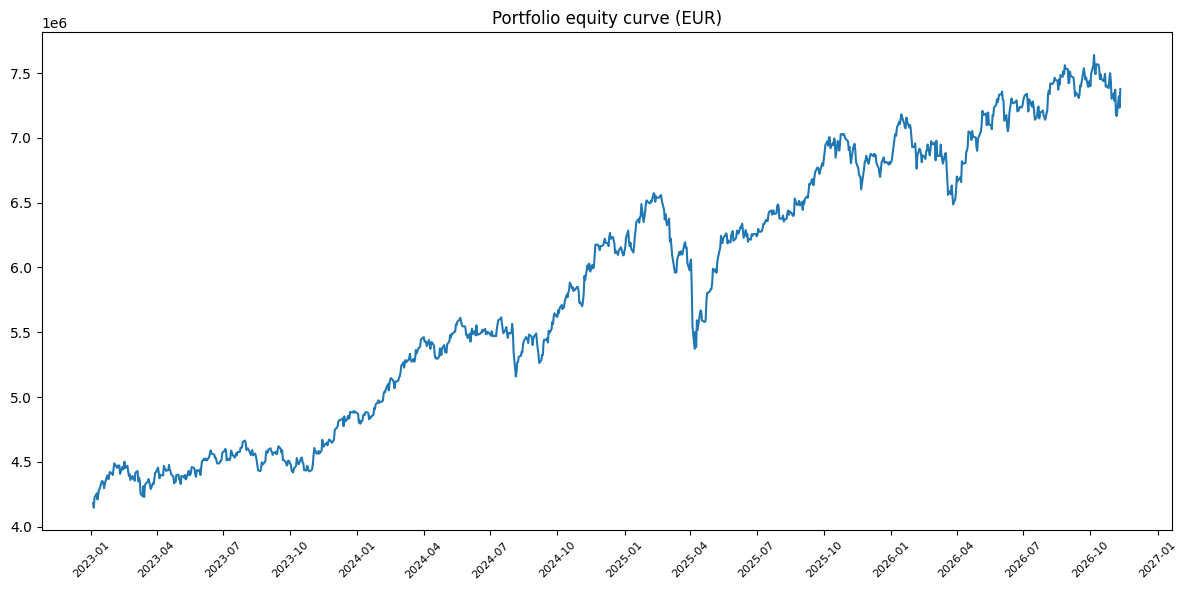

In [15]:
equity_curve = analysed_value * np.exp(portfolio_returns.cumsum() - portfolio_returns.sum())

plt.figure(figsize=(12, 6))
plt.plot(equity_curve)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.title("Portfolio equity curve (EUR)")
plt.xticks(rotation=45, fontsize=8)
plt.tight_layout()
plt.show()

### Maximum drawdown

Largest percentage drop from a running maximum, with the dates of the peak and of the trough.

In [16]:
running_max = equity_curve.cummax()
drawdown = equity_curve / running_max - 1
maximum_drawdown = drawdown.min()

date_min = drawdown.idxmin()
date_peak = equity_curve.loc[:date_min].idxmax()

print("Previous peak date:", date_peak)
print("Trough date:", date_min)
print("Peak value:", equity_curve.loc[date_peak])
print("Trough value:", equity_curve.loc[date_min])
print("Maximum drawdown:", maximum_drawdown)

Previous peak date: 2025-02-10 00:00:00
Trough date: 2025-04-07 00:00:00
Peak value: 6573991.563910555
Trough value: 5372391.298470662
Maximum drawdown: -0.18278092598054962


### Drawdown plot

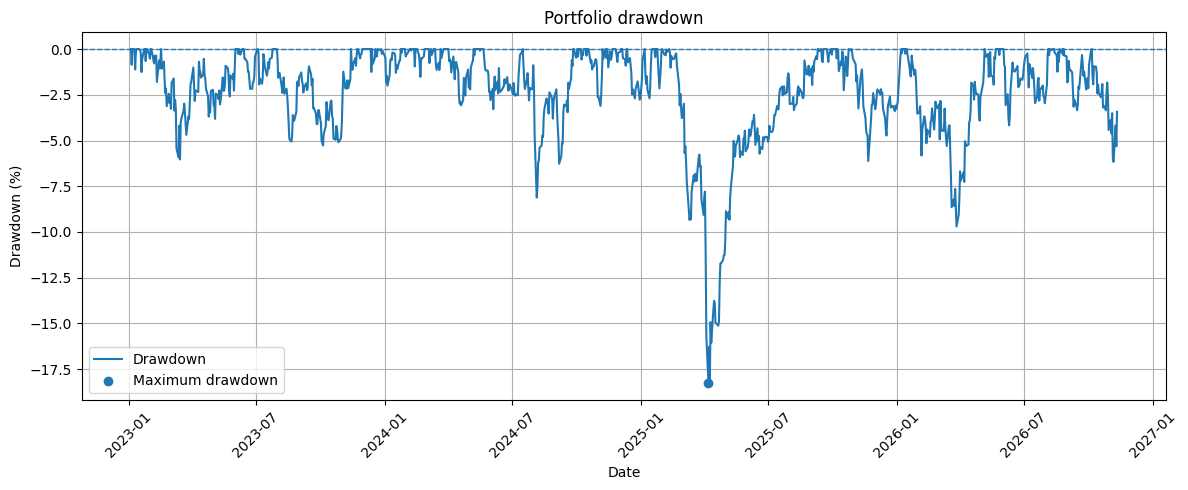

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(drawdown.index, drawdown * 100, label="Drawdown")
plt.axhline(y=0, linestyle="--", linewidth=1)
plt.scatter(date_min, drawdown.loc[date_min] * 100, label="Maximum drawdown", zorder=5)

plt.title("Portfolio drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Value at Risk and Conditional VaR

Historical VaR and CVaR (expected shortfall) on daily log returns, 1-day horizon. Losses are converted to EUR on the analysed value.

In [18]:
alpha = 1 - CONFIDENCE_LEVEL

percentile = np.percentile(portfolio_returns, alpha * 100)
var_pct = -percentile

worst_tail = portfolio_returns[portfolio_returns <= percentile]
cvar_pct = -worst_tail.mean()

var_eur = analysed_value * (1 - np.exp(-var_pct))
cvar_eur = analysed_value * (1 - np.exp(-cvar_pct))

print(f"VaR {CONFIDENCE_LEVEL:.0%}: {var_pct:.4f} ({var_eur:,.0f} EUR)")
print(f"CVaR {CONFIDENCE_LEVEL:.0%}: {cvar_pct:.4f} ({cvar_eur:,.0f} EUR)")

VaR 95%: 0.0120 (87,711 EUR)
CVaR 95%: 0.0181 (132,280 EUR)


### Correlation heatmap

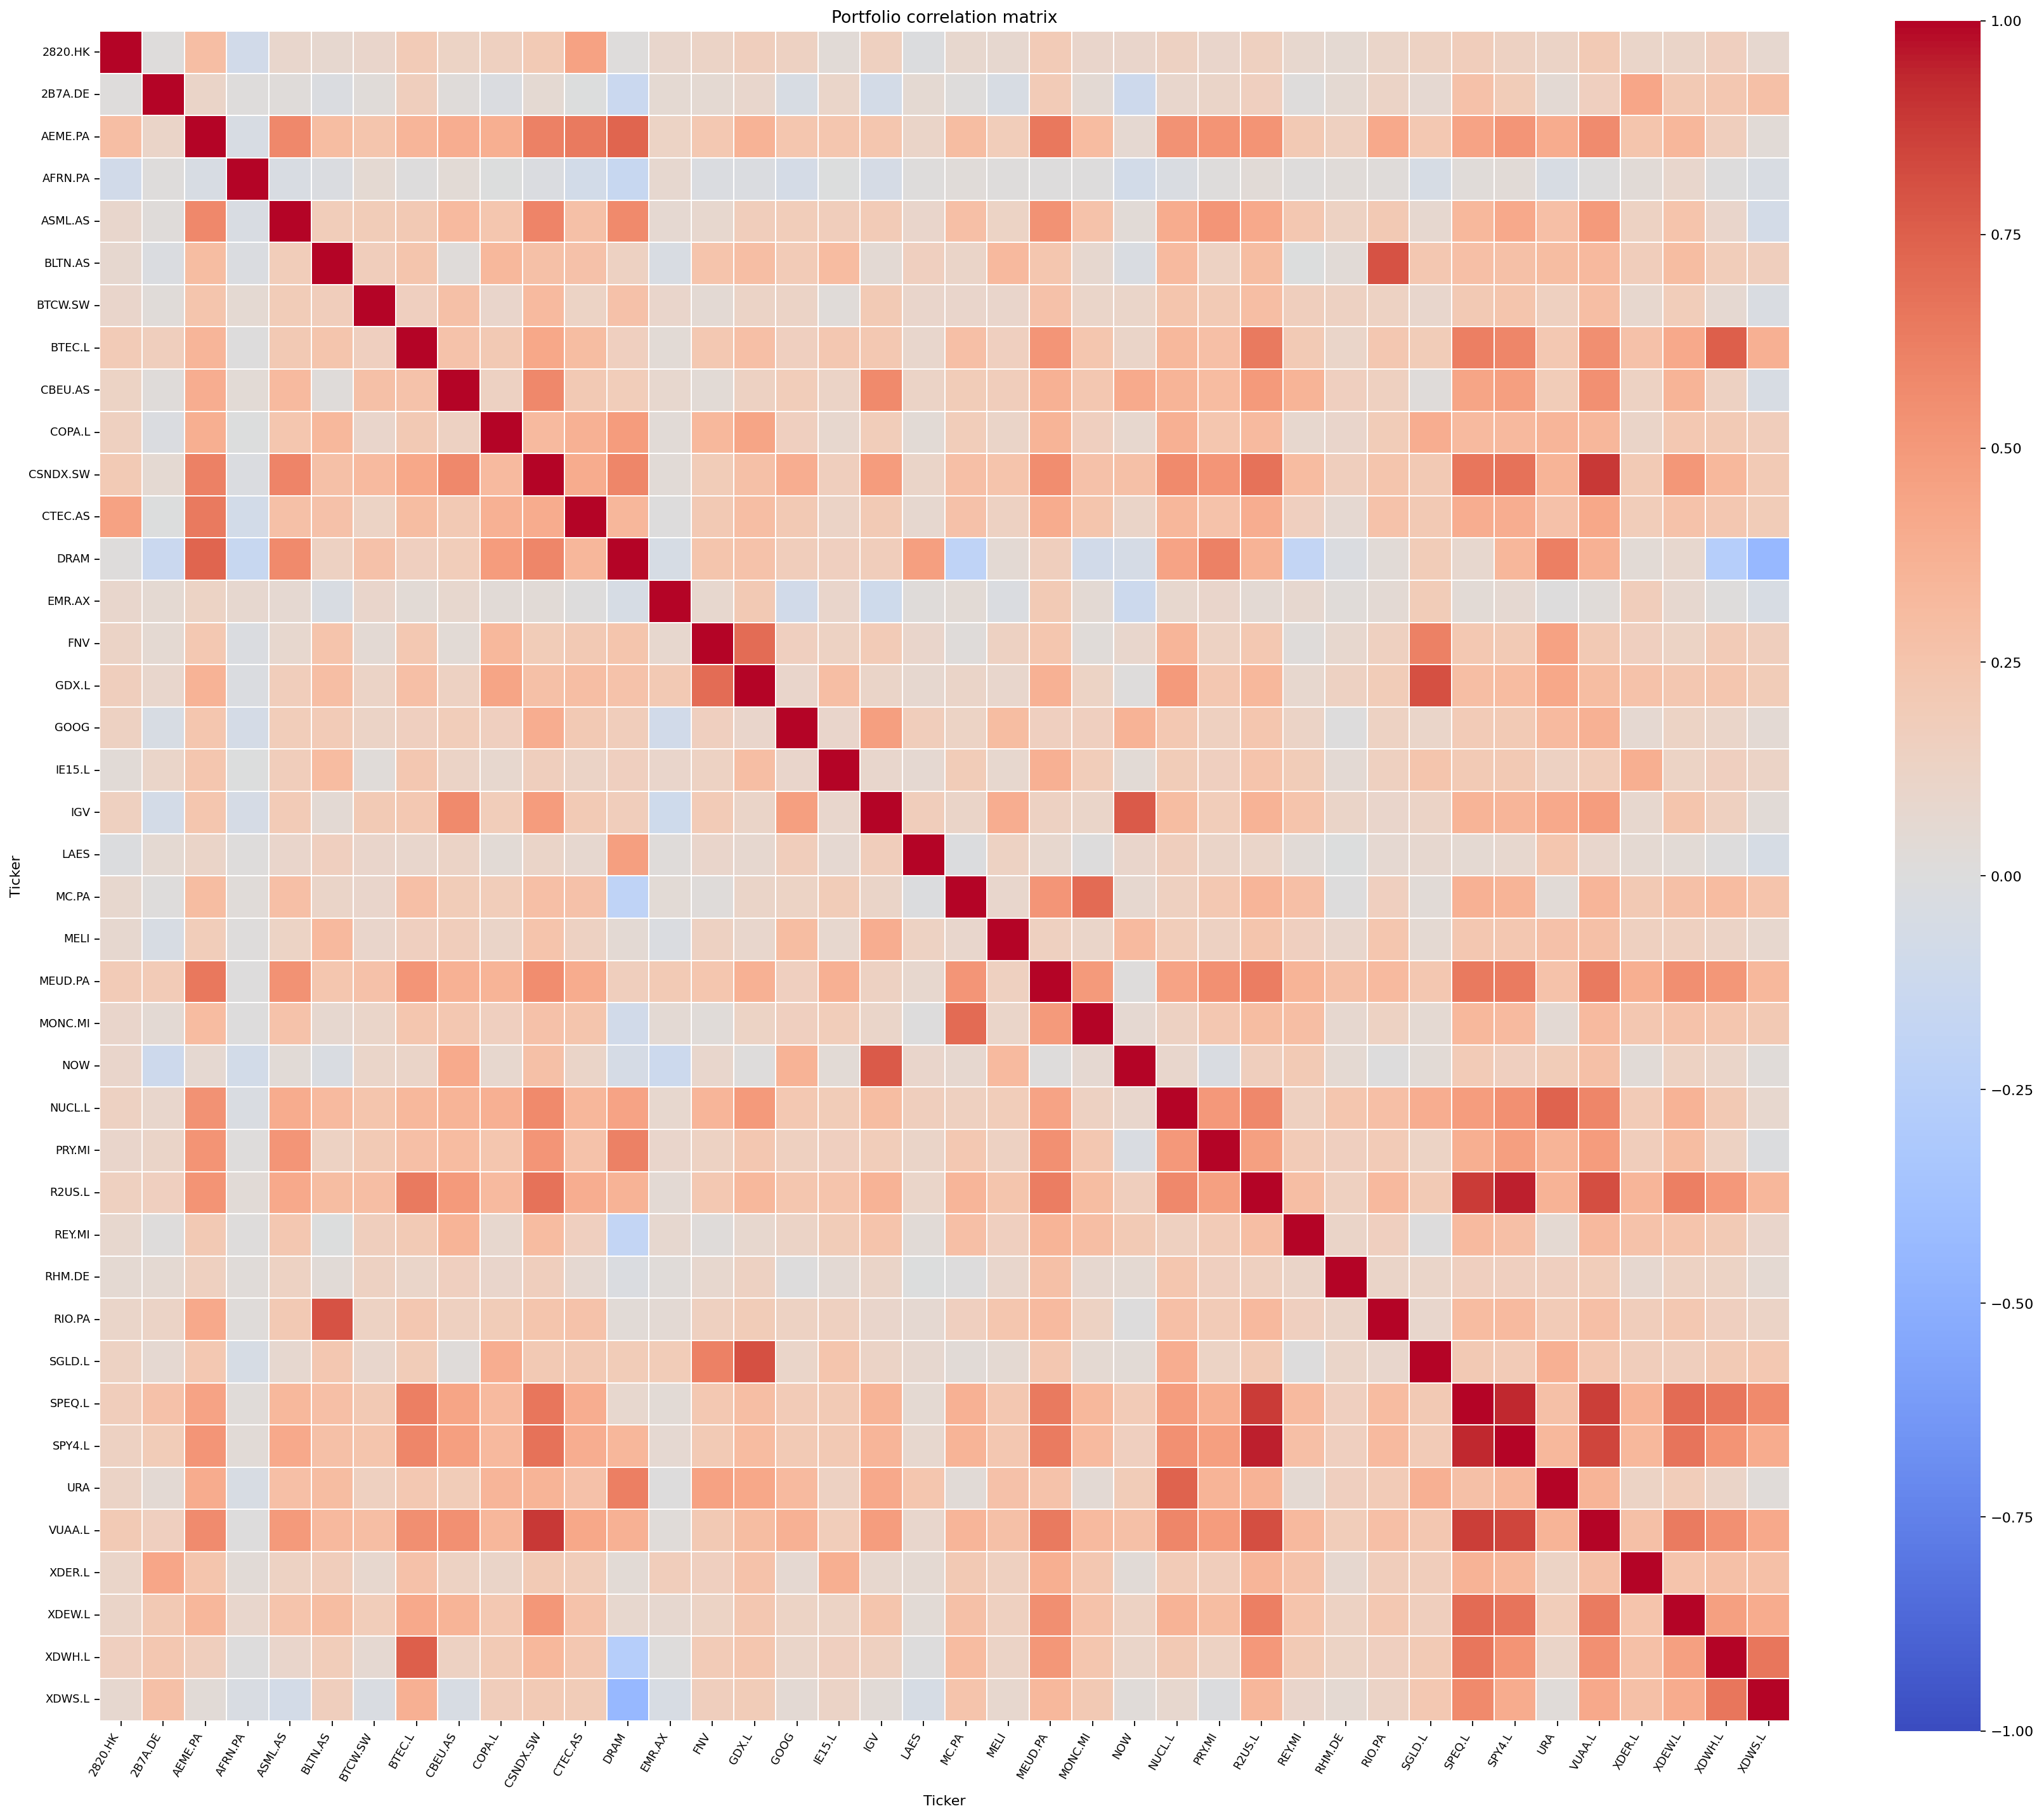

In [19]:
plt.figure(figsize=(22, 18), dpi=160)

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    annot=False,
    linewidths=0.2,
)

plt.xticks(rotation=60, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.title("Portfolio correlation matrix")
plt.tight_layout()